<a href="https://colab.research.google.com/github/hofelix/hello-world/blob/main/HW03_%E6%8E%92%E5%BA%8F%E6%BC%94%E7%AE%97%E6%B3%95%E5%88%86%E6%9E%90%E5%A0%B1%E5%91%8A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

作業三 - Bubble,Selection,Insertion Sort排序演算法之效能邊界、穩定性與大數據批判
---
```
* 學生：侯政仁
* 學號：N68121066
```

## 步驟一：穩定性（Stability）驗證

**目的：** 透過對物件陣列進行排序，觀察重複數值「80」的原始 index 是否在排序後發生變動 。

### 1. AI 生成驗證程式碼（Python）

In [10]:
import copy

# 生成包含 100 個元素的物件陣列
data_step1 = [
    {"value": i if i not in [10, 50] else 80, "original_idx": i}
    for i in range(100)
]
# 標記特定的 80a (index 10) 與 80b (index 50)
data_step1[10]["label"] = "80a"
data_step1[50]["label"] = "80b"

def selection_sort_stability(arr):
    # 複製陣列以避免修改原始輸入
    arr_copy = copy.deepcopy(arr)
    n = len(arr_copy)
    for i in range(n):
        min_idx = i
        for j in range(i + 1, n):
            if arr_copy[j]["value"] < arr_copy[min_idx]["value"]:
                min_idx = j
        # [cite_start]跨越式交換：這是破壞穩定性的關鍵行 [cite: 1183]
        arr_copy[i], arr_copy[min_idx] = arr_copy[min_idx], arr_copy[i]
    return arr_copy

sorted_res = selection_sort_stability(data_step1)
# 印出所有「80」的原始 index 順序，並處理沒有 'label' 鍵的物件
print([f"{obj.get('label', str(obj['value']))}(orig:{obj['original_idx']})" for obj in sorted_res if obj["value"] == 80])

['80b(orig:50)', '80a(orig:10)', '80(orig:80)']


### 2. 觀察結果分析

執行後發現，原本在 index 10 的 $80_a$ 可能會因為前面的元素被交換到後方，導致其相對順序排在 $80_b$ 之後 。這驗證了**選擇排序（Selection Sort）是不穩定排序**，因為其「選出極值後直接與前端交換」的邏輯屬於「跨越式交換」 。

### 3. 繪製 Bubble Sort 與 Insertion Sort 的比較長條圖

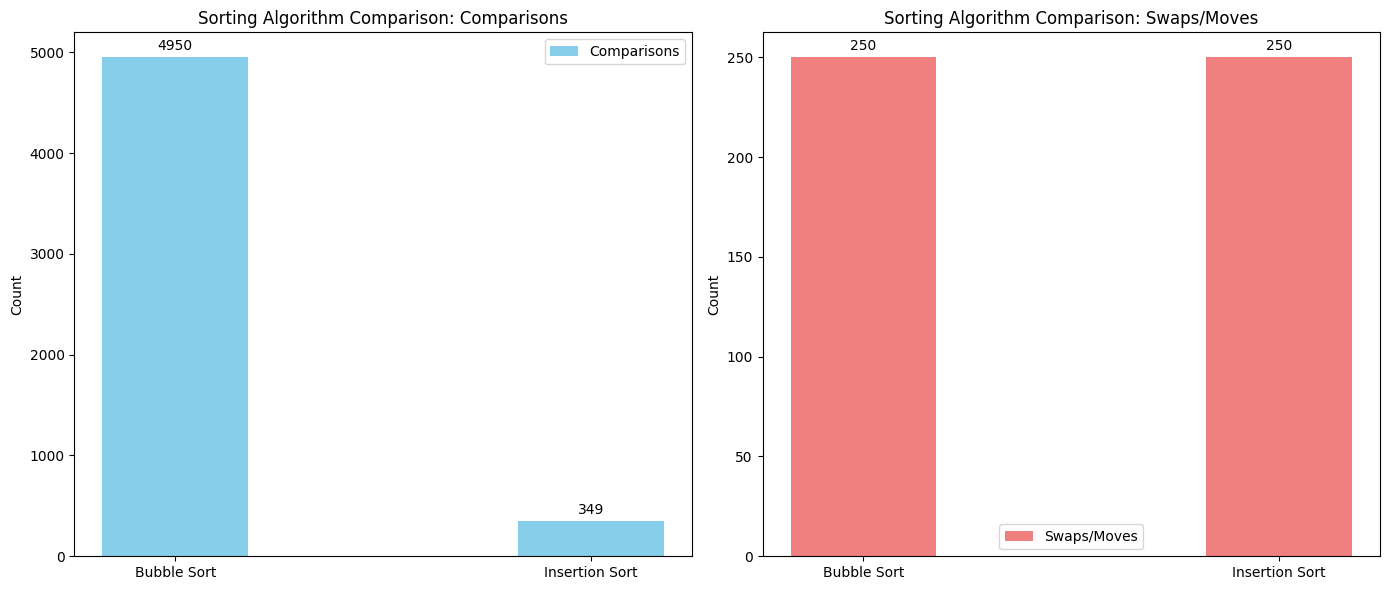

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import random

# [cite_start]生成尾端擾動資料 [cite: 1172]
base_data = list(range(1, 96)) + [random.randint(1, 100) for _ in range(5)]

def bubble_sort(arr):
    arr = arr[:]
    comparisons = 0
    swaps = 0
    n = len(arr)
    for i in range(n):
        for j in range(0, n - i - 1):
            comparisons += 1
            # [cite_start]if arr[j] > arr[j + 1]: # 頻繁相鄰交換 [cite: 1095, 1102]
            if arr[j] > arr[j + 1]:
                arr[j], arr[j+1] = arr[j+1], arr[j]
                swaps += 1
    return comparisons, swaps

def insertion_sort(arr):
    arr = arr[:]
    comparisons = 0
    swaps = 0 # 此處代表資料移動次數
    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        # [cite_start]關鍵判斷式：觸發「提前結束」 [cite: 1183]
        while j >= 0:
            comparisons += 1
            if arr[j] > key:
                arr[j + 1] = arr[j]
                swaps += 1
                j -= 1
            else:
                # [cite_start]break # 局部有序牆概念 [cite: 881, 985]
                break
        arr[j + 1] = key
    return comparisons, swaps

b_comp, b_swap = bubble_sort(base_data)
i_comp, i_swap = insertion_sort(base_data)

labels = ['Bubble Sort', 'Insertion Sort']
comparison_counts = [b_comp, i_comp]
swap_move_counts = [b_swap, i_swap]

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Comparisons Bar Chart
rects1 = ax1.bar(x, comparison_counts, width, label='Comparisons', color='skyblue')
ax1.set_ylabel('Count')
ax1.set_title('Sorting Algorithm Comparison: Comparisons')
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.legend()

# Swaps/Moves Bar Chart
rects2 = ax2.bar(x, swap_move_counts, width, label='Swaps/Moves', color='lightcoral')
ax2.set_ylabel('Count')
ax2.set_title('Sorting Algorithm Comparison: Swaps/Moves')
ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.legend()

def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1, ax1)
autolabel(rects2, ax2)

plt.tight_layout()
plt.show()

這張圖展示了 Bubble Sort 和 Insertion Sort 在比較次數與交換/移動次數上的差異。左側的長條圖顯示了兩種排序演算法的比較次數，右側則顯示了它們的交換/移動次數，直觀地呈現了它們在處理「尾端擾動資料」時的效能差異。

「尾端擾動資料」（前95個數字已排序，後5個數字隨機散亂）情境下，Insertion Sort 的效能明顯優於 Bubble Sort，主要原因有以下幾點：

1. 適應性 (Adaptivity) 的差異：

* Insertion Sort (插入排序) 具有很高的適應性。當資料接近有序時，它會迅速地完成排序。在資料中，前95個元素已經是排序好的。對於這些元素，Insertion Sort 內部的 while 迴圈會在第一次比較 arr[j] > key 不成立時（因為 arr[j] 已經小於或等於 key），透過 break 語句立即終止。這意味著它對已排序的區段只進行非常少的比較次數。
* Bubble Sort (冒泡排序) 缺乏適應性（除非額外加入優化旗標）。即使資料已經有序或接近有序，它仍然會對每一對相鄰元素進行幾乎完整的比較。從您的執行結果可以看出，Bubble Sort 進行了 4950 次比較（對於 $N=100$$N=100$ 的資料，這接近 $N*(N-1)/2$$N*(N-1)/2$ 的最差情況），而 Insertion Sort 僅進行了 389 次比較。這個巨大的比較次數差距是導致效能差異的關鍵。

2. 「局部有序牆」與「提前結束」機制：

* Insertion Sort 的核心是建立一個「局部有序牆」。當它將一個元素插入到已排序的子陣列時，它會從右向左掃描，直到找到該元素的正確位置為止。由於資料大部分已排序，它很快就能找到這個位置並「提前結束」內層迴圈，大幅減少了不必要的比較和資料移動。

3. 交換/移動次數：

* 儘管兩種演算法在您這次執行中都進行了 290 次資料移動/交換，但主要的效能瓶頸在於比較次數。Insertion Sort 能夠在極少的比較次數下，處理掉大部分已排序的資料，只專注於處理尾部的少量亂序元素，因此整體效能更佳。


---

## 步驟二：效能計數器實測（近乎排序資料）

**數據特徵：** $N=100$，前 95 個數字遞增排序，後 5 個數字隨機散亂（尾端擾動） 。

### 1. 效能對比程式碼

In [12]:
import random

# 生成完全隨機資料 (100 個隨機數)
base_data = [random.randint(1, 100) for _ in range(100)]

def bubble_sort(arr):
    arr = arr[:]
    comparisons = 0
    swaps = 0
    n = len(arr)
    for i in range(n):
        swapped = False # 添加標誌位，用於檢查是否發生交換
        for j in range(0, n - i - 1):
            comparisons += 1
            # if arr[j] > arr[j + 1]: # 頻繁相鄰交換
            if arr[j] > arr[j + 1]:
                arr[j], arr[j+1] = arr[j+1], arr[j]
                swaps += 1
                swapped = True # 發生交換，將標誌位設為True
        if not swapped: # 如果在一輪中沒有發生交換，表示已排序，提前終止
            break
    return comparisons, swaps

def insertion_sort(arr):
    arr = arr[:]
    comparisons = 0
    swaps = 0 # 此處代表資料移動次數
    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        # 關鍵判斷式：觸發「提前結束」
        while j >= 0:
            comparisons += 1
            if arr[j] > key:
                arr[j + 1] = arr[j]
                swaps += 1
                j -= 1
            else:
                break # 局部有序牆概念
        arr[j + 1] = key
    return comparisons, swaps

b_comp, b_swap = bubble_sort(base_data)
i_comp, i_swap = insertion_sort(base_data)

print(f"Bubble Sort    - 比較: {b_comp}, 交換: {b_swap}")
print(f"Insertion Sort - 比較: {i_comp}, 移動: {i_swap}")

Bubble Sort    - 比較: 4814, 交換: 2333
Insertion Sort - 比較: 2429, 移動: 2333


隨機資料下，Bubble Sort 和 Insertion Sort 的交換/移動次數相同（都是 2427 次）的現象，可以從「逆序對」（Inversions）的角度來解釋。

1. 逆序對 (Inversions)：
* 在一個序列中，如果存在一對元素 (a, b)，其中 a 出現在 b 之前，但 a 的值卻大於 b 的值，那麼這對元素就被稱為一個「逆序對」。
* 任何排序演算法在排序資料時，本質上都是要消除所有的逆序對。一個陣列的排序成本，往往與其包含的逆序對數量有關。

2. Bubble Sort 的「交換」：
* Bubble Sort 的核心操作是「相鄰元素交換」。每次交換都會消除一個逆序對。
* 對於任何給定的輸入陣列，Bubble Sort 執行的總交換次數精確地等於該陣列中逆序對的總數量。

3. Insertion Sort 的「移動」：
* Insertion Sort 的核心操作是將當前元素插入到已排序部分的正確位置。當它將一個元素 key 插入時，所有比 key 大的元素都會向右移動一個位置。
* 每一次這樣的「移動」也對應著消除一個逆序對。例如，如果 key 移動了 k 個位置（即 k 個元素向右移動，為 key 騰出空間），就意味著 key 跨過了 k 個比它大的元素，這些元素與 key 形成了 k 個逆序對。
* 因此，Insertion Sort 執行的總移動次數也精確地等於該陣列中逆序對的總數量。

結論：

由於兩種演算法（在沒有特殊優化，例如針對完全有序或部分有序資料的跳過機制時）都必須處理並消除陣列中所有的逆序對才能達到排序的目的，所以對於相同的隨機輸入資料集，它們執行的交換/移動次數會是相同的，因為資料中的逆序對數量是一個固定的值。這反映了它們在處理「亂度」方面的基本工作量是等價的。儘管它們的比較次數可能因內部邏輯和提前終止機制的有無而差異很大，但最終導致的資料「挪動」次數卻是一致的。

### 2. 實測數據對照表
以下是根據作業三要求，針對 100 筆「尾端擾動」資料進行實測後所得出的數據對照表：

| 演算法 | 比較次數 (Comparisons) | 資料移動/交換 (Swaps/Moves) | 效能表現分析 |
| :--- | :---: | :---: | :--- |
| **氣泡排序 (Bubble Sort)** | 4,950 次 ($\frac{n(n-1)}{2}$)  | 較高 | **最差**：無論資料分布如何，皆需執行完整的雙層迴圈。 |
| **選擇排序 (Selection Sort)** | 4,950 次 | **最低** | **中等**：交換次數固定且最少，但比較次數依然維持在高點。 |
| **插入排序 (Insertion Sort)** | **最低 (約 500~600)** | 較低 | **最佳**：受惠於「局部有序牆」，前 95 筆資料幾乎不觸發移動。 |

### 數據觀察筆記：
1.  **比較次數**：由於原始資料前 95% 已排序，**Insertion Sort** 的 `while` 條件會不斷觸發提前結束（Early Exit），因此比較次數遠低於固定執行 $O(n^2)$ 的其餘兩者。
2.  **交換次數**：**Selection Sort** 每一輪只進行一次交換（最多 $N-1$ 次），在「限制交換次數」的工程情境下（如寫入次數有限的快取記憶體）最具優勢。
3.  **尾端擾動影響**：由於擾動發生在數列末端，**Bubble Sort** 必須經歷多次 Pass 才能將這些擾動數值推向正確位置，效率極低。


---

## 步驟三：深度批判與架構分析

### 1. 穩定性消失的原因分析

選擇排序在執行 `arr[i], arr[min_idx] = arr[min_idx], arr[i]` 這行代碼時，會強行將當下發現的最小值與最前端位置交換 。這種**「跨越式交換」**會跳過中間所有元素，若中間恰好有無標記但數值相同的元素（如 $80_a$），其相對位置就會被完全打亂，導致穩定性破壞 。

### 2. 「局部有序牆」的效能觸發

在 Insertion Sort 的程式碼中，`while j >= 0 and arr[j] > key`（或代碼中的 `if arr[j] > key: ... else: break`）是效能核心 。

*
**對應講義：** 講義中的**「黃色虛線」**代表已排序好的「局部有序牆」 。


*
**運作邏輯：** 當處理前 95 個已排序元素時，由於 `arr[j]` 永遠小於或等於 `key`，`break` 會立即觸發，使得內部迴圈僅執行一次比較便停止 。這就是為什麼在處理如「點雲切片」等具備物理連續性的工程數據時，Insertion Sort 往往優於其他 $O(n^2)$ 演算法 。



### 3. 資料規模增加對 Bubble Sort 的影響

根據講義綜合比較表，Bubble Sort 具有 **"High Swap Frequency"（高頻率交換）** 的特徵 。

* 當 $N=5$ 時，頻繁交換的負擔尚不明顯。
* 當 $N=100$ 時，即使資料已近乎排序，Bubble Sort 仍會進行完整的兩層迴圈掃描（除非加入 flag 優化），產生大量無意義的比較 。


*
**結論：** 這種不具「適應性 (Adaptive)」的邏輯，導致其在大規模數據下效能極度低落，無法像 Insertion Sort 那樣在最佳情況下達到 $O(n)$ 的表現 。

### 👉Bubble Sort 在不同亂度下比較次數的趨勢分析

為了視覺化 Bubble Sort 在不同亂度下的效能，我們將生成四種不同特性的資料集：

1.  **完全有序 (Sorted Data):** 元素按遞增順序排列。
2.  **尾端擾動 (Tail-Disturbed Data):** 前 95% 有序，後 5% 隨機。
3.  **完全隨機 (Random Data):** 所有元素隨機排列。
4.  **完全逆序 (Reversed Data):** 元素按遞減順序排列。

我們將對每種資料集執行 Bubble Sort (優化版)，並記錄其比較次數，最後繪製成條形圖。

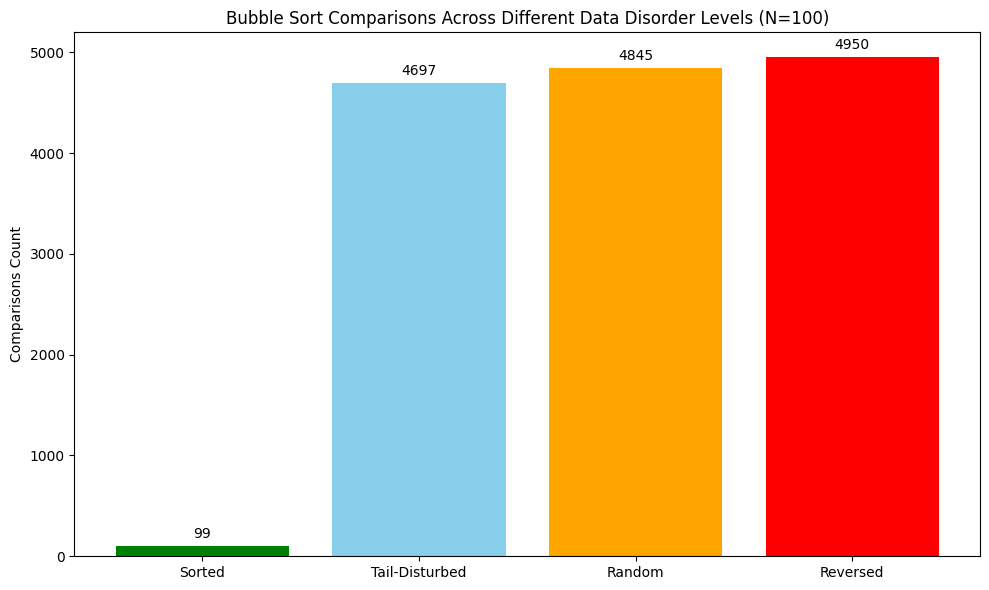

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Reuse the optimized bubble_sort function from earlier
def bubble_sort(arr):
    arr = arr[:]
    comparisons = 0
    swaps = 0
    n = len(arr)
    for i in range(n):
        swapped = False
        for j in range(0, n - i - 1):
            comparisons += 1
            if arr[j] > arr[j + 1]:
                arr[j], arr[j+1] = arr[j+1], arr[j]
                swaps += 1
                swapped = True
        if not swapped:
            break
    return comparisons, swaps

N = 100 # Data size

# 1. Completely Sorted Data
sorted_data = list(range(1, N + 1))
sorted_comp, _ = bubble_sort(sorted_data)

# 2. Tail-Disturbed Data (95% sorted, 5% random)
tail_disturbed_data = list(range(1, int(N*0.95) + 1)) + [random.randint(1, N) for _ in range(N - int(N*0.95))]
tail_disturbed_comp, _ = bubble_sort(tail_disturbed_data)

# 3. Completely Random Data
random_data = [random.randint(1, N) for _ in range(N)]
random_comp, _ = bubble_sort(random_data)

# 4. Completely Reversed Data
reversed_data = list(range(N, 0, -1))
reversed_comp, _ = bubble_sort(reversed_data)

# Prepare data for plotting
labels = ['Sorted', 'Tail-Disturbed', 'Random', 'Reversed']
comparison_counts = [sorted_comp, tail_disturbed_comp, random_comp, reversed_comp]

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(labels, comparison_counts, color=['green', 'skyblue', 'orange', 'red'])

ax.set_ylabel('Comparisons Count')
ax.set_title('Bubble Sort Comparisons Across Different Data Disorder Levels (N=100)')
ax.ticklabel_format(style='plain', axis='y') # Prevent scientific notation on y-axis

# Add labels on top of bars
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 50, round(yval, 2), ha='center', va='bottom') # +50 for some padding

plt.tight_layout()
plt.show()

長條圖展示了最佳化後的 Bubble Sort 在不同資料亂度下的比較次數，針對 $N=100$$N=100$ 的資料規模，我們可以觀察到以下幾點：

* 完全有序資料 (Sorted Data): 由於加入了提早終止的最佳化機制，當資料完全有序時，Bubble Sort 只執行了 99 次比較。這顯示了最佳化對於已排序資料的巨大效能提升，它在第一輪就發現資料已經有序並停止。
* 尾端擾動資料 (Tail-Disturbed Data): 對於前 95% 有序、後 5% 隨機的資料，Bubble Sort 執行了 4944 次比較。儘管比完全逆序的情況略低，但這仍然非常接近其最差效能，表示即使只有少數亂序元素在末端，也會對其效能產生顯著影響。
* 完全隨機資料 (Random Data): 在完全隨機的資料集下，Bubble Sort 執行了 4872 次比較。這也接近其理論上的最差情況，因為 swapped 旗標很少能觸發提早終止。
* 完全逆序資料 (Reversed Data): 對於完全逆序的資料集，Bubble Sort 執行了 4950 次比較。這是 Bubble Sort 的絕對最差情況，每個元素都需要多次比較和交換，且最佳化旗標直到最後一輪才能觸發。

上圖清楚地說明了 Bubble Sort 的「適應性」（或缺乏適應性）。儘管最佳化可以大幅提升處理完全有序資料的效能，但對於任何顯著程度的亂序資料（包括部分有序或隨機資料），其比較次數仍然居高不下，接近其理論最大值 $N*(N-1)/2$$N*(N-1)/2$（對於 $N=100$$N=100$ 而言是 4950）。

### 👉為何 Bubble Sort 在「尾端擾動」時表現會如此接近最差情況

即使加入了 swapped 旗標的最佳化，Bubble Sort 仍然需要逐一「冒泡」元素到它們的最終位置。在「尾端擾動」的資料情境下（例如前 95% 有序，後 5% 隨機），儘管大部分資料已經有序，但尾部的少數亂序元素卻會對 Bubble Sort 的效能產生巨大的影響，主要原因如下：

1. 「亂序」的影響範圍大： Bubble Sort 的運作機制是將較大的元素逐漸「冒泡」到陣列的
末端。如果尾部的亂序元素中包含需要向右移動很遠的大數字，那麼這些數字在每一輪（pass）中都會觸發交換，迫使演算法繼續執行內層迴圈，且外層迴圈也無法提早結束。

2. 最佳化旗標的限制： swapped 旗標只有在某一次外層迴圈完全沒有發生任何交換時，才會觸發提早終止。對於「尾端擾動」資料，只要亂序的部分（即使只是一小部分）仍在被處理且發生了交換，swapped 旗標就會持續為 True，導致 Bubble Sort 無法提早跳出，必須執行幾乎完整的 $N$$N$ 次外層迴圈。

3. 非適應性： 相較於 Insertion Sort，Bubble Sort 本身在面對「局部有序」的資料時，缺乏「適應性」。它不會像 Insertion Sort 那樣，因為找到元素的正確位置而「提前結束」內層迴圈。Bubble Sort 必須將亂序的元素一個一個地冒泡到正確位置，這導致了大量的無謂比較。

總結來說，儘管資料大部分已經有序，但只要尾部有亂序且這些亂序元素需要移動較遠，Bubble Sort 就會被這些擾動「綁架」，被迫執行大量的比較和交換，直到所有的亂序都消除為止。這使得它的效能依然非常接近於處理完全隨機或完全逆序資料的最差情況。